# 35. Nonnormal Matrices and Perturbation of Matrix Functions
Run the cells in order. Keep `lafp.py` in the same folder.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from lafp import *
%matplotlib inline

Pseudospectra, shown as level curves of $\log_{10}\lVert(zI-A)^{-1}\rVert^{-1}=\log_{10}s_{\min}(zI-A)$ at $\varepsilon=10^{-1},10^{-2},\dots,10^{-8}$, with eigenvalues as dots. Left: a normal matrix; the curves are circles of radius $\varepsilon$. Middle: a $16\times16$ upper bidiagonal matrix with $0.6$ on the diagonal and $1$ above; a single eigenvalue, but the $10^{-8}$-pseudospectrum is a disc of radius about $0.3$. Right: the Grcar matrix ($32\times32$, $-1$ on the subdiagonal, $1$ on the diagonal and three superdiagonals), whose pseudospectra are large regions extending far beyond its eigenvalues.

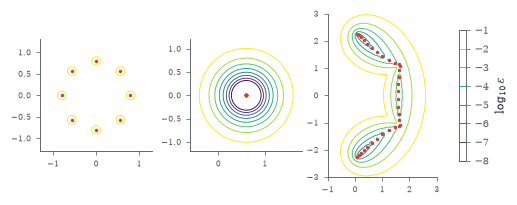

In [2]:
def smin_grid(M, xr, yr, N=110):
    xs, ys = np.linspace(*xr, N), np.linspace(*yr, N); S = np.zeros((N, N)); I = np.eye(len(M))
    for i, y in enumerate(ys):
        for j, x in enumerate(xs): S[i, j] = np.linalg.svd((x + 1j * y) * I - M, compute_uv=False)[-1]
    return xs, ys, S
rng = np.random.default_rng(0); Qn, _ = np.linalg.qr(rng.normal(size=(8, 8)) + 1j * rng.normal(size=(8, 8)))
Nrm = Qn @ np.diag(np.exp(2j * np.pi * np.arange(8) / 8) * 0.8) @ Qn.conj().T
Bid = 0.6 * np.eye(16) + np.eye(16, k=1)
ng = 32; Grc = np.eye(ng) - np.eye(ng, k=-1) + sum(np.eye(ng, k=j) for j in (1, 2, 3))
fig, axs = plt.subplots(1, 3, figsize=(W, 1.75))
for ax, M, xr, yr in [(axs[0], Nrm, (-1.3, 1.3), (-1.3, 1.3)), (axs[1], Bid, (-0.6, 1.8), (-1.2, 1.2)), (axs[2], Grc, (-1, 3), (-3, 3))]:
    xs, ys, S = smin_grid(M, xr, yr); cs = ax.contour(xs, ys, np.log10(S), levels=np.arange(-8, 0), cmap="viridis", linewidths=0.6)
    ev = np.linalg.eigvals(M); ax.plot(ev.real, ev.imag, ".", color=RED, ms=2.5); ax.set_aspect("equal"); ax.tick_params(labelsize=5)
fig.colorbar(cs, ax=axs, shrink=0.8, label=r"$\log_{10}\varepsilon$")

The pseudospectrum as a union of perturbed spectra. Eigenvalues of the Grcar matrix plus $100$ random complex perturbations $E$ with $\lVert E\rVert=10^{-3}$ (dots) fill out the region bounded by the $10^{-3}$-pseudospectral boundary (black curve), far from the unperturbed eigenvalues (red). Random perturbations rarely reach the boundary, which requires the worst-case rank-one perturbation $-rv^*$ of the theorem.

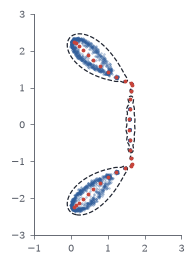

In [3]:
xs, ys, S = smin_grid(Grc, (-1, 3), (-3, 3), N=120)
fig, ax = plt.subplots(figsize=(W * 0.45, W * 0.5))
for _ in range(100):
    E = rng.normal(size=(ng, ng)) + 1j * rng.normal(size=(ng, ng)); E *= 1e-3 / np.linalg.norm(E, 2); ev = np.linalg.eigvals(Grc + E); ax.plot(ev.real, ev.imag, ".", color=BLUE, ms=0.8, alpha=0.5)
ax.contour(xs, ys, np.log10(S), levels=[-3], colors=INK, linewidths=0.8); ev0 = np.linalg.eigvals(Grc); ax.plot(ev0.real, ev0.imag, ".", color=RED, ms=3); ax.set_aspect("equal")

Transient growth of a stable nonnormal matrix. $A$ is $20\times20$ upper bidiagonal with $-1$ on the diagonal and $1.5$ above, so every eigenvalue is $-1$ and $e^{tA}\to0$. Yet $\lVert e^{tA}\rVert$ (blue) rises above $10^{3}$ before decaying. The pseudospectral lower bound $\sup_\varepsilon\alpha_\varepsilon(A)/\varepsilon$ (red dashed, computed on a grid) guarantees a hump of the right order, here about one order of magnitude below the true peak; the eigenvalues predict only decay.

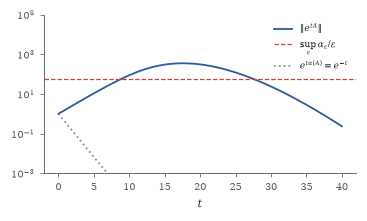

In [4]:
from scipy.linalg import expm
Ab = -np.eye(20) + 1.5 * np.eye(20, k=1); ts = np.linspace(0, 40, 200); nrm = [np.linalg.norm(expm(t * Ab), 2) for t in ts]
xs, ys, S = smin_grid(Ab, (-3, 1.6), (-2.3, 2.3), N=90); GX, GY = np.meshgrid(xs, ys); best = 0
for e in np.logspace(-8, 0, 40):
    inside = S < e
    if inside.any(): best = max(best, GX[inside].max() / e)
fig, ax = plt.subplots(figsize=(W * 0.7, 1.9))
ax.semilogy(ts, nrm, color=BLUE, label=r"$\|e^{tA}\|$"); ax.axhline(best, color=RED, ls="--", lw=0.8, label=r"$\sup_\varepsilon \alpha_\varepsilon/\varepsilon$")
ax.semilogy(ts, np.exp(-ts), ":", color=GRAY, label=r"$e^{t\alpha(A)}=e^{-t}$"); ax.set_ylim(1e-3, 1e5); ax.set_xlabel("$t$"); ax.legend(fontsize=6)

The absolute value is not operator-Lipschitz. Take $A$ Hermitian with eigenvalues $\pm1.6^k$, $k<n/2$, and the perturbation direction $H$ coupling positive and negative eigenvalues through the Toeplitz matrix $1/(k-l+\frac12)$ (whose norm stays below $\pi$). The derivative of $X\mapsto|X|$ at $A$ in direction $H$, computed exactly by the Daleckii–Krein formula, has operator norm growing like $\log n$ relative to $\lVert H\rVert$ (blue, with fitted line), while in the Frobenius norm the ratio stays below $1$ (red). The divided differences of $|t|$ at $a>0>-b$ are $\frac{a-b}{a+b}\approx\pm1$, so the derivative acts like the triangular truncation of Chapter 29.

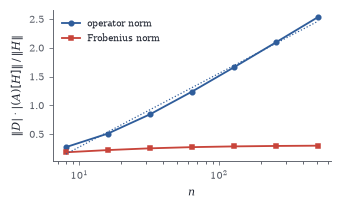

In [5]:
ns = [8, 16, 32, 64, 128, 256, 512]; rop, rfr = [], []
for n in ns:
    m = n // 2; g = 1.6 ** np.arange(m); lam = np.r_[g, -g]; i_ = np.arange(m); T = 1.0 / (i_[:, None] - i_[None, :] + 0.5)
    Hm = np.zeros((n, n)); Hm[:m, m:] = T; Hm[m:, :m] = T.T
    Lab = (np.abs(lam)[:, None] - np.abs(lam)[None, :]) / (lam[:, None] - lam[None, :] + np.eye(n)); Lab[np.diag_indices(n)] = np.sign(lam)
    D = Lab * Hm; rop.append(np.linalg.norm(D, 2) / np.linalg.norm(Hm, 2)); rfr.append(np.linalg.norm(D) / np.linalg.norm(Hm))
fig, ax = plt.subplots(figsize=(W * 0.65, 1.8))
ax.semilogx(ns, rop, "o-", color=BLUE, ms=3, label="operator norm"); ax.semilogx(ns, rfr, "s-", color=RED, ms=3, label="Frobenius norm")
cf = np.polyfit(np.log(ns), rop, 1); ax.semilogx(ns, np.polyval(cf, np.log(ns)), ":", color=BLUE, lw=0.8)
ax.set_xlabel("$n$"); ax.set_ylabel(r"$\|D|\cdot|(A)[H]\|\,/\,\|H\|$"); ax.legend(fontsize=6)

In [6]:
n = 10; Ak = 0.5 * np.eye(n) + 0.8 * np.eye(n, k=1); I = np.eye(n)
K = max((r - 1) / np.linalg.svd(r * np.exp(1j * th) * I - Ak, compute_uv=False)[-1] for r in np.linspace(1.001, 3, 150) for th in np.linspace(0, 2 * np.pi, 48))
P = np.eye(n); sup_pow = 0
for k in range(200): sup_pow = max(sup_pow, np.linalg.norm(P, 2)); P = P @ Ak
print(f"Kreiss constant ~ {K:.3f}   sup ||A^k|| = {sup_pow:.3f}   e*n*K = {np.e * n * K:.1f}")

Kreiss constant ~ 5.241   sup ||A^k|| = 19.181   e*n*K = 142.5
